<a href="https://colab.research.google.com/github/querogab/projeto_desafios_tecnicos_ad05/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Desafio 02 · Estatística — Tema 2: Posto de Saúde (Triagem)

Rede VidaMais Saúde (dados 100% fictícios). Base: CSVs `pacientes.csv` (dimensão) e `atendimentos.csv` (fato) do repositório do Desafio.

## Passo 1 — Pergunta de negócio


- **Pergunta de negócio:** o tempo de espera de cada cor de triagem está dentro do tempo-alvo do Protocolo Manchester?
- **Coluna de análise:** `tempo_espera_min` (minutos entre a chegada e o início do atendimento)
- **Decisão que o resultado apoiaria:** em quais cores reforçar a equipe ou rever o fluxo de atendimento

### Célula 01 · Importações

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Célula 02 · Carregar os arquivos CSV

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "pacientes"   # ex.: "livros"
NOME_TABELA_FATO = "atendimentos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Mounted at /content/drive
Selecione os arquivos CSV (pacientes e atendimentos). Pode escolher os dois de uma vez:


Saving pacientes.csv to pacientes.csv
Saving atendimentos.csv to atendimentos.csv
pacientes.csv -> pacientes.csv
atendimentos.csv -> atendimentos.csv
pacientes -> 10500 linhas
atendimentos -> 42000 linhas


### Célula 03 · Conhecendo a tabela dimensão

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10500 linhas e 6 colunas (variáveis)


,paciente_id,nome,data_nascimento,sexo,bairro,tipo_convenio
0,1,Juan Lopes,1983-12-08,M,Vila Madre Gertrudes 1ª Seção,SUS
1,2,Rafael Abreu,2017-06-21,outro,Vila Antena,SUS
2,3,Dra. Julia Montenegro,1989-01-28,M,São Francisco Das Chagas,SUS
3,4,Thiago Caldeira,1936-02-02,M,Santo Antônio,SUS
4,5,Letícia Porto,1994-08-19,F,Vila Tirol,SUS


### Célula 04 · Conhecendo a tabela fato

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,atendimento_id,paciente_id,data_hora_chegada,sintoma_principal,nivel_triagem,tempo_espera_min,profissional_responsavel,desfecho
0,1,9633,2025-01-18 21:49:41,falta de ar,verde,37,Enfermeira 19,internado
1,2,2676,2025-04-27 08:55:07,falta de ar,amarelo,28,Enfermeiro 10,alta
2,3,4503,2026-07-08 06:54:14,vômito/náusea,amarelo,20,Enfermeiro 21,alta
3,4,7532,2026-05-04 12:21:15,tontura,verde,87,Tecnico Enfermagem 12,alta
4,5,2728,2025-07-12 08:48:22,dor de cabeça,verde,39,Tecnico Enfermagem 06,alta


### Célula 05 · Tipos das colunas

In [5]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   atendimento_id            42000 non-null  int64 
 1   paciente_id               42000 non-null  int64 
 2   data_hora_chegada         42000 non-null  object
 3   sintoma_principal         42000 non-null  object
 4   nivel_triagem             42000 non-null  object
 5   tempo_espera_min          42000 non-null  int64 
 6   profissional_responsavel  42000 non-null  object
 7   desfecho                  42000 non-null  object
dtypes: int64(3), object(5)
memory usage: 2.6+ MB


### Célula 06 · Valores ausentes

In [6]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
atendimento_id              0
paciente_id                 0
data_hora_chegada           0
sintoma_principal           0
nivel_triagem               0
tempo_espera_min            0
profissional_responsavel    0
desfecho                    0
dtype: int64


### Célula 07 · Linhas duplicadas

In [7]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Célula 08 · Chave estrangeira

In [8]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "paciente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "paciente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


### Leitura da conferência


- 42.000 atendimentos e 10.500 pacientes, nenhuma linha duplicada.
- A chave estrangeira bate: todo atendimento aponta para um paciente que existe (True).
- Nenhum valor ausente em nenhuma coluna, inclusive tempo_espera_min.

### Célula 09 · Checar a coluna numérica

In [9]:
# (código-base do guia do Desafio 02; nomes de tabelas, colunas e eixos preenchidos com apoio de IA)
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_espera_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


### Célula 10 · Medidas estatísticas

In [10]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,63.40
Mediana,51.00
Moda,0.00
Desvio padrão,51.79
Variância,2681.74
Mínimo,0.00
Máximo,358.00
Amplitude,358.00


Média - mediana: 12.4


## Passo 6 — Frases de insight


- **A média de tempo_espera_min é 63,4 min**. O paciente espera pouco mais de uma hora pra ser atendido
- **A mediana de tempo_espera_min é 51 min**. Esperas muito longas puxam a média pra cima
- **O desvio padrão de tempo_espera_min é 51,8 min**. A espera varia muito de um paciênte para o outro
- **Decisão final:** Como a espera é desigual, o melhor caminho é analisar por cor de triagem.

### Célula 11 · Juntar a fato com a dimensão

In [11]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 42000 | depois da junção: 42000


### Célula 12 · Comparar grupos por uma coluna da fato

In [12]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "nivel_triagem"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
nivel_triagem,,,,
azul,6349,149.47,150.0,57.38
verde,16934,69.62,69.0,29.34
amarelo,14631,34.64,34.0,16.78
laranja,3318,8.06,7.0,6.70
vermelho,768,1.73,0.0,2.66


### Leitura da comparação por nível de triagem


- O azul (menos urgente) tem a maior espera: média de 149,5 min e mediana de 150 min. As duas quase iguais mostram que é o padrão do grupo
- O azul também tem o maior desvio (57,4 min): é onde a espera mais varia. Já o vermelho tem o menor (2,7 min), porque quase todos são atendidos na hora.
- A ordem das esperas segue a gravidade, então a triagem funciona. Amarelo (34,6), verde (69,6) e azul (149,5) ficam bem abaixo do alvo. As cores graves têm folga mínima: o laranja tem média de 8,1 min para um alvo de 10, e o vermelho, que deveria ser imediato, tem média de 1,7 min, então parte das emergências espera

### Célula 13 · Comparar grupos por uma coluna da dimensão

In [13]:

COLUNA_GRUPO = "tipo_convenio"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
tipo_convenio,,,,
convenio,8259,64.24,52.0,52.21
particular,4851,63.70,51.0,51.80
SUS,28890,63.11,51.0,51.66


### Leitura da comparação por tipo de convênio

- O convênio tem a maior média (64,2 min), mas só 1 minuto acima do SUS (63,1 min)
- Os desvios também são quase iguais (51,7 a 52,2 min): a espera varia do mesmo jeito nos três grupos
- Médias e medianas parecidas mostram que o tipo de convênio não muda o tempo de espera: a fila segue a gravidade (cor da triagem), não a forma de pagamento.

### Célula 14 · Regra do IQR

In [14]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -59.00 a 173.00
Outliers: 2161 de 42000 valores
Maiores valores: [358, 346, 342, 341, 330]
Menores valores: [0, 0, 0, 0, 0]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [15]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,63.40,55.38
Mediana,51.00,48.00
Desvio padrão,51.79,39.09


### Leitura e decisão registrada (outliers e ausentes)

-A regra do IQR marcou 2.161 atendimentos (cerca de 5%) com espera acima de 173 min. Sem eles, a média cai de 63,4 para 55,4 min e o desvio de 51,8 para 39,1 min. A mediana muda pouco: de 51 para 48 min
- **Decisão:** manter. Os valores altos são esperas plausíveis de casos não urgentes (azul, alvo de até 240 min), não erros. Excluí-los esconderia justamente os pacientes que mais esperam, que interessam à gestão.
- **Valores ausentes:** a Célula 06 mostrou zero ausentes em todas as colunas, então não foi preciso preencher nem remover nada.

### Célula 16 · Assimetria (skew)

In [16]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.42


### Célula 17 · Percentis

In [17]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10      9.0
0.25     28.0
0.50     51.0
0.75     86.0
0.90    133.0
Name: tempo_espera_min, dtype: float64


### Célula 18 · Quantidade de valores por faixa

In [18]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_espera_min,
"(-0.358, 71.6]",28024
"(71.6, 143.2]",10409
"(143.2, 214.8]",2775
"(214.8, 286.4]",741
"(286.4, 358.0]",51


### Leitura da distribuição

- A assimetria é 1,42, positiva: a maioria espera pouco, e uma minoria espera muito mais, formando uma cauda à direita. Por isso a média (63,4) fica acima da mediana (51)
- (O percentil diz até quanto espera uma fatia dos pacientes: 10% → 9 · 25% → 28 · 50% → 51 · 75% → 86 · 90% → 133 min.
- A primeira faixa, até ~72 min, concentra cerca de 28 mil atendimentos (2 em cada 3). A última, acima de ~286 min, tem só 51
- A maioria dos pacientes espera entre 28 e 86 minutos, e poucos passam de 133 minutos.

### Célula 19 · Histograma

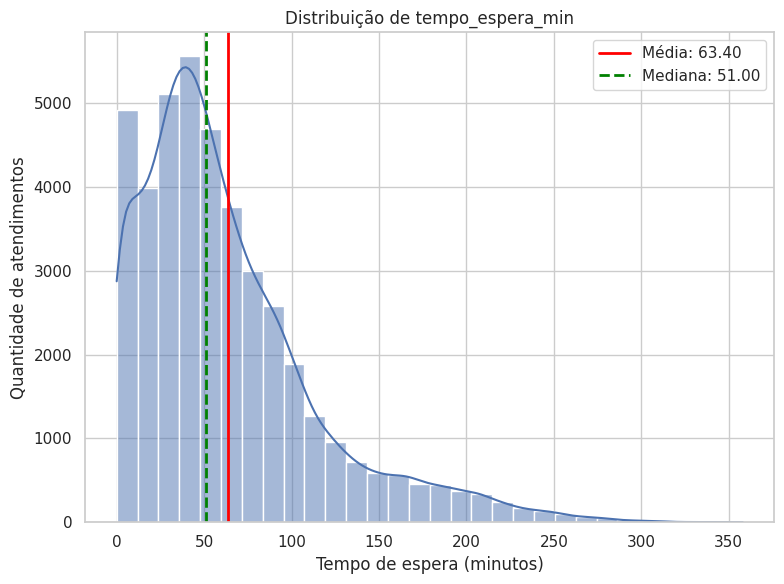

In [19]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de espera (minutos)")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de atendimentos")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

### Célula 20 · Boxplot

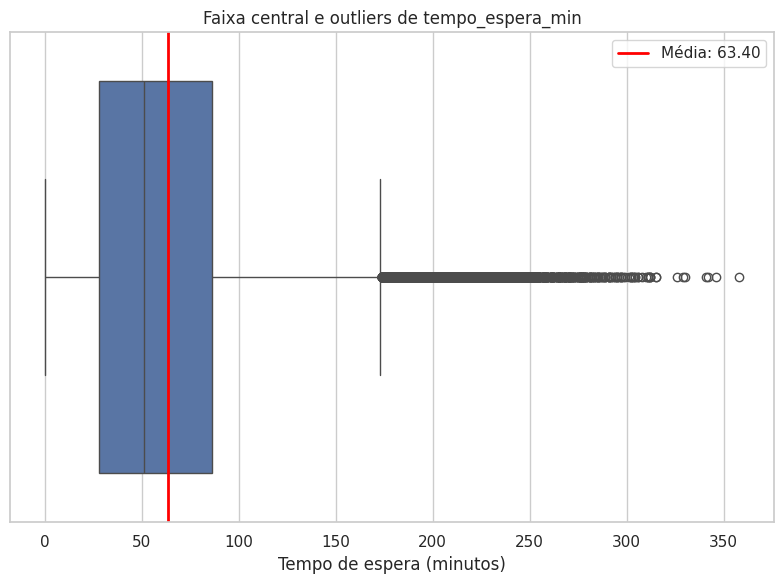

In [20]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de espera (minutos)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

## Passo 10 — Recomendação

Recomendo reforçar o atendimento das cores laranja e vermelha: o laranja já espera em média 8,1 min para um alvo de 10, e o vermelho, que deveria ser imediato, tem média de 1,7 min.